<a href="https://colab.research.google.com/github/Aprio-wile/computer_vision/blob/main/YOLO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ultralytics
!pip install mediapipe

In [ ]:
import cv2
import numpy as np
from ultralytics import YOLO
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import cv2



# ***load yolo model***

In [ ]:
yolo_model = YOLO('yolov8n.pt')

# ***initialize mediapipe pose***

In [ ]:
# Download a pose model bundle if you haven't already:
!wget -nc https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/1/pose_landmarker_full.task

base_options = python.BaseOptions(model_asset_path='pose_landmarker_full.task')
options1 = vision.PoseLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE)
detector1 = vision.PoseLandmarker.create_from_options(options1)

File ‘pose_landmarker_full.task’ already there; not retrieving.



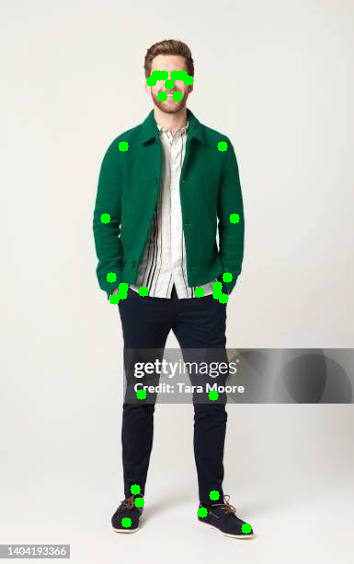

In [ ]:
# for draw landmimport cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

# 1. Load your image (upload an image to your Colab files and change the path here)
image_path = '/content/images-7.jpeg' # Replace with your image file name
image = cv2.imread(image_path)

if image is None:
    print("Error: Could not load image. Please check the file path.")
else:
    # Convert BGR to RGB (MediaPipe and Matplotlib expect RGB)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # 2. Convert to MediaPipe Image format
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=image_rgb)

    # 3. Run pose detection
    detection_result = detector1.detect(mp_image)

    # 4. Draw landmarks manually using OpenCV
    annotated_image = image.copy()
    height, width, _ = annotated_image.shape

    if detection_result.pose_landmarks:
        for pose_landmarks in detection_result.pose_landmarks:
            # Draw circles on each landmark point
            for landmark in pose_landmarks:
                x_px = int(landmark.x * width)
                y_px = int(landmark.y * height)
                cv2.circle(annotated_image, (x_px, y_px), 5, (0, 255, 0), -1) # Green dots

    # 5. Display the annotated image in Colab
    cv2_imshow(annotated_image)

In [ ]:
options2 = vision.PoseLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.VIDEO)
detector2 = vision.PoseLandmarker.create_from_options(options2)

In [ ]:
video_path = '/content/12199286_2160_3840_30fps.mp4'
cap = cv2.VideoCapture(video_path)

# Re-initialize detector2 to reset its internal timestamp tracking state
options2 = vision.PoseLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.VIDEO)
detector2 = vision.PoseLandmarker.create_from_options(options2)

fps = int(cap.get(cv2.CAP_PROP_FPS))
if fps <= 0:
    fps = 30  # Fallback to standard 30 FPS if metadata is missing

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

frame_count = 0
last_timestamp_ms = -1

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter('output_pose.mp4', fourcc, fps, (width, height))

while cap.isOpened():
  success, frame = cap.read()

  if not success:
    break

  # Calculate a monotonically increasing timestamp
  frame_timestamp_ms = int(frame_count * (1000 / fps))

  # Force strict monotonicity to prevent MediaPipe exceptions
  if frame_timestamp_ms <= last_timestamp_ms:
      frame_timestamp_ms = last_timestamp_ms + 1

  last_timestamp_ms = frame_timestamp_ms

  frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
  mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)

  detection_result = detector2.detect_for_video(mp_image, frame_timestamp_ms)

  # Prepare an image to draw annotations on
  frame_annotated = frame.copy()

  if detection_result.pose_landmarks:
    for pose_landmarks in detection_result.pose_landmarks:
      for landmark in pose_landmarks:
        x_px = int(landmark.x * width)
        y_px = int(landmark.y * height)
        cv2.circle(frame_annotated, (x_px, y_px), 14, (0,255,0), -1) # Green dots

  out.write(frame_annotated)
  frame_count += 1

cap.release()
out.release()
cv2.destroyAllWindows()